In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

required_files = [
    "train_images.npy",
    "test_images.npy",
    "labels.csv",
    "train_idx.txt",
    "val_idx.txt",
    "classes.txt",
    "model.py",
    "check_format.py",
    "results_template.json",
]

# Search the extraction folder and its subfolders
found_files = {}
for root, dirs, files in os.walk("/content/drive/MyDrive/cv_bootcamp"):
    for file in files:
        if file in required_files:
            found_files[file] = os.path.join(root, file)

for file in required_files:
    if file in found_files:
        size_mb = os.path.getsize(found_files[file]) / (1024 * 1024)
        print(f"✅ {file} — {size_mb:.2f} MB")
    else:
        print(f"❌ MISSING: {file}")

✅ train_images.npy — 146.48 MB
✅ test_images.npy — 29.30 MB
✅ labels.csv — 0.56 MB
✅ train_idx.txt — 0.25 MB
✅ val_idx.txt — 0.03 MB
✅ classes.txt — 0.00 MB
✅ model.py — 0.00 MB
✅ check_format.py — 0.02 MB
✅ results_template.json — 0.00 MB


In [ ]:

import os
import numpy as np
import pandas as pd
import torch

DATA_DIR = "/content/drive/MyDrive/cv_bootcamp"

# Locate files in case the ZIP created a nested folder
def find_file(filename):
    for root, dirs, files in os.walk(DATA_DIR):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"Could not find {filename}")

# 1. Check image arrays
train_images = np.load(find_file("train_images.npy"), mmap_mode="r")
test_images = np.load(find_file("test_images.npy"), mmap_mode="r")

print("TRAIN IMAGES")
print("Shape:", train_images.shape, "| dtype:", train_images.dtype)

print("\nTEST IMAGES")
print("Shape:", test_images.shape, "| dtype:", test_images.dtype)

# 2. Check labels
labels = pd.read_csv(find_file("labels.csv"))
print("\nLABELS")
print("Shape:", labels.shape)
print("Columns:", labels.columns.tolist())
print(labels.head())

# 3. Check train/validation indices
train_idx = np.loadtxt(find_file("train_idx.txt"), dtype=int)
val_idx = np.loadtxt(find_file("val_idx.txt"), dtype=int)

print("\nINDICES")
print("Training indices:", len(train_idx))
print("Validation indices:", len(val_idx))
print("Train/validation overlap:",
      len(set(train_idx).intersection(set(val_idx))))

# 4. Check GPU
print("\nGPU")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Don't start training yet.")


TRAIN IMAGES
Shape: (50000, 32, 32, 3) | dtype: uint8

TEST IMAGES
Shape: (10000, 32, 32, 3) | dtype: uint8

LABELS
Shape: (50000, 4)
Columns: ['index', 'noisy_label', 'synthetic_label', 'clean_label']
   index  noisy_label  synthetic_label  clean_label
0      0            4                6            6
1      1            9                6            9
2      2            0                9            9
3      3            5                4            4
4      4            1                1            1

INDICES
Training indices: 45000
Validation indices: 5000
Train/validation overlap: 0

GPU
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4


In [ ]:

# Step 7: Dataset consistency and label-noise analysis

import numpy as np
import pandas as pd

# Verify label row indices
print("LABEL INDEX CHECK")
print("Indices match CSV row order:",
      np.array_equal(labels["index"].to_numpy(), np.arange(len(labels))))

# Verify train/validation indices
all_idx = np.concatenate([train_idx, val_idx])

print("\nSPLIT CHECK")
print("All indices in valid range:",
      np.all((all_idx >= 0) & (all_idx < len(labels))))
print("Indices are unique:", len(np.unique(all_idx)) == len(all_idx))
print("Splits cover all 50,000 images:",
      len(np.unique(all_idx)) == 50000)

# Verify label values
label_cols = ["noisy_label", "synthetic_label", "clean_label"]

print("\nLABEL VALUE CHECK")
for col in label_cols:
    vals = sorted(labels[col].unique())
    print(f"{col}: {vals} | valid CIFAR-10 labels:",
          set(vals).issubset(set(range(10))))

# Measure noisy-label rate using clean labels for analysis only
noisy_mismatch = labels["noisy_label"] != labels["clean_label"]
synthetic_mismatch = labels["synthetic_label"] != labels["clean_label"]

print("\nLABEL NOISE")
print(f"Noisy-label mismatches: {noisy_mismatch.sum()} / {len(labels)}")
print(f"Noisy-label noise rate: {noisy_mismatch.mean():.2%}")
print(f"Synthetic-label mismatches: {synthetic_mismatch.sum()} / {len(labels)}")
print(f"Synthetic-label noise rate: {synthetic_mismatch.mean():.2%}")

# Confusion matrix: rows = clean labels, columns = noisy labels
print("\nCONFUSION MATRIX (rows=clean, columns=noisy)")
print(pd.crosstab(
    labels["clean_label"],
    labels["noisy_label"],
    rownames=["Clean"],
    colnames=["Noisy"],
).reindex(index=range(10), columns=range(10), fill_value=0))

print("\nDataset checks completed.")


LABEL INDEX CHECK
Indices match CSV row order: True

SPLIT CHECK
All indices in valid range: True
Indices are unique: True
Splits cover all 50,000 images: True

LABEL VALUE CHECK
noisy_label: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] | valid CIFAR-10 labels: True
synthetic_label: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] | valid CIFAR-10 labels: True
clean_label: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] | valid CIFAR-10 labels: True

LABEL NOISE
Noisy-label mismatches: 20104 / 50000
Noisy-label noise rate: 40.21%
Synthetic-label mismatches: 20104 / 50000
Synthetic-label noise rate: 40.21%

CONFUSION MATRIX (rows=clean, columns=noisy)
Noisy     0     1     2     3     4     5     6     7     8     9
Clean                   

In [ ]:

import os
import sys
import time
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Find the supplied files
def find_file(filename):
    for root, dirs, files in os.walk("/content/drive/MyDrive/cv_bootcamp"):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"Missing file: {filename}")

model_path = find_file("model.py")
sys.path.insert(0, os.path.dirname(model_path))

from model import ResNet18

device = torch.device("cuda")
torch.backends.cudnn.benchmark = True

# Load data
images = np.load(find_file("train_images.npy"), mmap_mode="r")
labels_df = pd.read_csv(find_file("labels.csv"))
train_idx = np.loadtxt(find_file("train_idx.txt"), dtype=int)

# Standard CIFAR-10 training augmentations
transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

class CIFARDataset(Dataset):
    def __init__(self, indices):
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])
        image = Image.fromarray(np.array(images[idx]))
        x = transform(image)
        y = int(labels_df.iloc[idx]["noisy_label"])
        return x, y

loader = DataLoader(
    CIFARDataset(train_idx),
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# Build the exact supplied model from scratch
model = ResNet18(num_classes=10).to(device)
optimizer = torch.optim.SGD(
    model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4
)
criterion = torch.nn.CrossEntropyLoss()

print("Model:", type(model).__name__)
print("Trainable parameters:",
      f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print("GPU:", torch.cuda.get_device_name(0))
print("Batch size: 128")
print("Training batches per epoch:", len(loader))

# Benchmark 30 batches; this is NOT a full epoch
model.train()
times = []
torch.cuda.synchronize()
start_all = time.time()

for batch_num, (x, y) in enumerate(loader):
    if batch_num >= 30:
        break

    start = time.time()
    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)
    output = model(x)
    loss = criterion(output, y)
    loss.backward()
    optimizer.step()

    torch.cuda.synchronize()
    times.append(time.time() - start)

elapsed = time.time() - start_all
avg_batch = sum(times[5:]) / len(times[5:]) if len(times) > 5 else sum(times)/len(times)
estimated_epoch = avg_batch * len(loader)

print("\nTIMING RESULTS")
print("Batches completed:", len(times))
print(f"Elapsed time: {elapsed:.1f} seconds")
print(f"Average batch time (after warm-up): {avg_batch:.3f} seconds")
print(f"Estimated training time per epoch: {estimated_epoch/60:.1f} minutes")
print(f"Estimated 60-epoch training time: {estimated_epoch*60/3600:.1f} hours")
print("\nNote: Estimates exclude validation and other overhead.")


Model: ResNet
Trainable parameters: 11,173,962
GPU: Tesla T4
Batch size: 128
Training batches per epoch: 352

TIMING RESULTS
Batches completed: 30
Elapsed time: 15.4 seconds
Average batch time (after warm-up): 0.092 seconds
Estimated training time per epoch: 0.5 minutes
Estimated 60-epoch training time: 0.5 hours

Note: Estimates exclude validation and other overhead.


In [ ]:

import os
import json

def find_file(filename):
    for root, dirs, files in os.walk("/content/drive/MyDrive/cv_bootcamp"):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(filename)

print("=== MODEL FILE ===")
with open(find_file("model.py"), "r") as f:
    print(f.read())

print("\n=== RESULTS TEMPLATE ===")
with open(find_file("results_template.json"), "r") as f:
    template = json.load(f)
print(json.dumps(template, indent=2))

print("\n=== FORMAT CHECKER ===")
print("Found:", find_file("check_format.py"))


=== MODEL FILE ===
"""ResNet-18 for 32x32 CIFAR images (the standard CIFAR variant: 3x3 stem, no max-pool).

Everyone must use this exact architecture, trained from scratch (no pretrained weights).

    from model import ResNet18
    net = ResNet18(num_classes=10)

You may wrap it (e.g. two copies for co-training) but do not change the layers.
"""
import torch.nn as nn
import torch.nn.functional as F


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, 1, stride=stride, bias=False),
  

In [ ]:

import os
import shutil

BASE = "/content/drive/MyDrive/cv_bootcamp"
SUBMISSION = "/content/drive/MyDrive/cv_bootcamp/submission"

# Create the required submission folders
os.makedirs(f"{SUBMISSION}/code", exist_ok=True)
os.makedirs(f"{SUBMISSION}/predictions", exist_ok=True)

# Copy the supplied model into our code folder
model_source = None
for root, dirs, files in os.walk(BASE):
    if "model.py" in files:
        model_source = os.path.join(root, "model.py")
        break

if model_source is None:
    raise FileNotFoundError("model.py not found")

shutil.copy2(model_source, f"{SUBMISSION}/code/model.py")

# Copy the format checker and its required index file
checker_source = None
for root, dirs, files in os.walk(BASE):
    if "check_format.py" in files:
        checker_source = os.path.join(root, "check_format.py")
        break

if checker_source is None:
    raise FileNotFoundError("check_format.py not found")

shutil.copy2(checker_source, f"{SUBMISSION}/code/check_format.py")
os.makedirs(f"{SUBMISSION}/code/data", exist_ok=True)
shutil.copy2(
    find_file("train_idx.txt"),
    f"{SUBMISSION}/code/data/train_idx.txt"
)

print("Workspace prepared:")
for root, dirs, files in os.walk(SUBMISSION):
    print(root, "->", files)


Workspace prepared:
/content/drive/MyDrive/cv_bootcamp/submission -> []
/content/drive/MyDrive/cv_bootcamp/submission/code -> ['model.py', 'check_format.py']
/content/drive/MyDrive/cv_bootcamp/submission/code/data -> ['train_idx.txt']
/content/drive/MyDrive/cv_bootcamp/submission/predictions -> []


In [ ]:

from pathlib import Path

script = r'''
import os
from pathlib import Path
import random
import argparse
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from model import ResNet18


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class CIFARArrayDataset(Dataset):
    def __init__(self, images, indices, labels=None, transform=None):
        self.images = images
        self.indices = np.asarray(indices, dtype=np.int64)
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, pos):
        idx = int(self.indices[pos])
        image = Image.fromarray(np.asarray(self.images[idx]))
        if self.transform:
            image = self.transform(image)
        if self.labels is None:
            return image, idx
        return image, int(self.labels[idx])


class IndexedDataset(Dataset):
    def __init__(self, images, indices, transform):
        self.images = images
        self.indices = np.asarray(indices, dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, pos):
        idx = int(self.indices[pos])
        image = Image.fromarray(np.asarray(self.images[idx]))
        return self.transform(image), idx


def make_model(device):
    # Use the organizer-provided architecture, initialized from scratch.
    model = ResNet18(num_classes=10)
    return model.to(device)


@torch.no_grad()
def predict_indices(model, loader, device, total_count):
    model.eval()
    predictions = np.full(total_count, -1, dtype=np.int64)
    for images, indices in loader:
        images = images.to(device, non_blocking=True)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        predictions[np.asarray(indices, dtype=np.int64)] = preds
    return predictions


def accuracy(preds, targets, indices):
    indices = np.asarray(indices, dtype=np.int64)
    return float(np.mean(preds[indices] == targets[indices]))


def save_test_predictions(model, images, transform, device, out_path):
    indices = np.arange(len(images))
    ds = IndexedDataset(images, indices, transform)
    loader = DataLoader(
        ds, batch_size=256, shuffle=False, num_workers=2,
        pin_memory=(device.type == "cuda")
    )
    preds = predict_indices(model, loader, device, len(images))
    if np.any(preds < 0):
        raise RuntimeError("Some test predictions are missing.")
    pd.DataFrame({"id": indices, "pred": preds}).to_csv(out_path, index=False)
    print(f"Saved {out_path}")


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--data-dir", default="/content/drive/MyDrive/cv_bootcamp")
    parser.add_argument("--out-dir", default="/content/drive/MyDrive/cv_bootcamp/submission")
    parser.add_argument("--epochs", type=int, default=60)
    parser.add_argument("--batch-size", type=int, default=128)
    parser.add_argument("--seed", type=int, default=42)
    args = parser.parse_args()

    if args.epochs < 1 or args.epochs > 60:
        raise ValueError("Epoch count must be between 1 and 60.")

    set_seed(args.seed)
    torch.backends.cudnn.benchmark = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)
    if device.type == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))

    # Locate the dataset files, including if they are inside a nested folder.
    data_dir = Path(args.data_dir)
    def locate(filename):
        direct = data_dir / filename
        if direct.exists():
            return direct
        matches = list(data_dir.rglob(filename))
        if not matches:
            raise FileNotFoundError(f"Cannot find {filename} under {data_dir}")
        return matches[0]

    train_images = np.load(locate("train_images.npy"), mmap_mode="r")
    test_images = np.load(locate("test_images.npy"), mmap_mode="r")
    labels_df = pd.read_csv(locate("labels.csv"))
    labels_df = labels_df.sort_values("index")
    noisy = labels_df["noisy_label"].to_numpy(dtype=np.int64)
    clean = labels_df["clean_label"].to_numpy(dtype=np.int64)

    train_idx = np.loadtxt(locate("train_idx.txt"), dtype=np.int64)
    val_idx = np.loadtxt(locate("val_idx.txt"), dtype=np.int64)

    if len(train_idx) != 45000 or len(val_idx) != 5000:
        raise ValueError("Expected 45,000 train indices and 5,000 validation indices.")

    # CIFAR-10 normalization.
    mean = (0.4914, 0.4822, 0.4465)
    std = (0.2470, 0.2435, 0.2616)
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    eval_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    os.makedirs(args.out_dir, exist_ok=True)
    os.makedirs(os.path.join(args.out_dir, "predictions"), exist_ok=True)
    checkpoint_dir = os.path.join(args.out_dir, "checkpoints")
    os.makedirs(checkpoint_dir, exist_ok=True)

    train_eval_ds = IndexedDataset(train_images, train_idx, eval_transform)
    train_eval_loader = DataLoader(
        train_eval_ds, batch_size=256, shuffle=False, num_workers=2,
        pin_memory=(device.type == "cuda")
    )
    val_ds = IndexedDataset(train_images, val_idx, eval_transform)
    val_loader = DataLoader(
        val_ds, batch_size=256, shuffle=False, num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    # Validation images are predicted once per epoch; compare predictions to
    # noisy and clean labels separately. Clean labels are diagnostics only
    # for the noisy-label model, never used for its training or selection.
    def val_metrics(model):
        val_preds = predict_indices(model, val_loader, device, len(train_images))
        return (
            accuracy(val_preds, noisy, val_idx),
            accuracy(val_preds, clean, val_idx)
        )

    # -------- Task 1: clean-reference model --------
    print("\n=== Training Task 1 clean-reference model ===")
    clean_ds = CIFARArrayDataset(
        train_images, train_idx, labels=clean, transform=train_transform
    )
    clean_loader = DataLoader(
        clean_ds, batch_size=args.batch_size, shuffle=True, num_workers=2,
        pin_memory=(device.type == "cuda")
    )
    clean_model = make_model(device)
    clean_optimizer = torch.optim.SGD(
        clean_model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4
    )
    clean_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        clean_optimizer, T_max=args.epochs
    )
    criterion = nn.CrossEntropyLoss()

    for epoch in range(1, args.epochs + 1):
        clean_model.train()
        running_loss = 0.0
        for x, y in clean_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            clean_optimizer.zero_grad(set_to_none=True)
            loss = criterion(clean_model(x), y)
            loss.backward()
            clean_optimizer.step()
            running_loss += loss.item()
        clean_scheduler.step()
        if epoch == 1 or epoch % 5 == 0 or epoch == args.epochs:
            val_noisy, val_clean = val_metrics(clean_model)
            print(
                f"[clean] epoch {epoch:02d}/{args.epochs} "
                f"loss={running_loss/len(clean_loader):.4f} "
                f"val_noisy={val_noisy:.4f} val_clean={val_clean:.4f}"
            )

    torch.save(clean_model.state_dict(), os.path.join(checkpoint_dir, "t1_clean_ref_final.pt"))
    save_test_predictions(
        clean_model, test_images, eval_transform, device,
        os.path.join(args.out_dir, "predictions", "t1_clean_ref.csv")
    )
    clean_val_noisy, clean_val_clean = val_metrics(clean_model)

    # -------- Tasks 1 & 2: noisy-label CE baseline --------
    print("\n=== Training Task 1/2 noisy-label CE baseline ===")
    noisy_ds = CIFARArrayDataset(
        train_images, train_idx, labels=noisy, transform=train_transform
    )
    noisy_loader = DataLoader(
        noisy_ds, batch_size=args.batch_size, shuffle=True, num_workers=2,
        pin_memory=(device.type == "cuda")
    )
    noisy_model = make_model(device)
    noisy_optimizer = torch.optim.SGD(
        noisy_model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4
    )
    noisy_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        noisy_optimizer, T_max=args.epochs
    )

    # Store epoch-by-epoch diagnostics and select the early-stop checkpoint
    # using noisy-label validation accuracy only.
    dynamics = []
    best_val_noisy = -1.0
    best_epoch = 1
    best_state_path = os.path.join(checkpoint_dir, "t2_early_stop.pt")
    correct_subset = train_idx[noisy[train_idx] == clean[train_idx]]
    mislabeled_subset = train_idx[noisy[train_idx] != clean[train_idx]]

    for epoch in range(1, args.epochs + 1):
        noisy_model.train()
        running_loss = 0.0
        for x, y in noisy_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            noisy_optimizer.zero_grad(set_to_none=True)
            loss = criterion(noisy_model(x), y)
            loss.backward()
            noisy_optimizer.step()
            running_loss += loss.item()
        noisy_scheduler.step()

        # Evaluate predictions on unaugmented training images for diagnostics.
        train_preds = predict_indices(
            noisy_model, train_eval_loader, device, len(train_images)
        )
        train_acc_correct = accuracy(train_preds, noisy, correct_subset)
        train_acc_mislabeled = accuracy(train_preds, noisy, mislabeled_subset)
        val_noisy, val_clean = val_metrics(noisy_model)

        dynamics.append({
            "epoch": epoch,
            "train_acc_correct": train_acc_correct,
            "train_acc_mislabeled": train_acc_mislabeled,
            "val_acc_noisy": val_noisy,
            "val_acc_clean": val_clean,
        })

        print(
            f"[noisy] epoch {epoch:02d}/{args.epochs} "
            f"loss={running_loss/len(noisy_loader):.4f} "
            f"train_correct_subset={train_acc_correct:.4f} "
            f"train_mislabeled_subset={train_acc_mislabeled:.4f} "
            f"val_noisy={val_noisy:.4f} val_clean={val_clean:.4f}"
        )

        if val_noisy > best_val_noisy:
            best_val_noisy = val_noisy
            best_epoch = epoch
            torch.save(noisy_model.state_dict(), best_state_path)

    pd.DataFrame(dynamics).to_csv(
        os.path.join(args.out_dir, "predictions", "t2_dynamics.csv"), index=False
    )
    torch.save(noisy_model.state_dict(), os.path.join(checkpoint_dir, "t1_noisy_ce_final.pt"))

    # Task 1 uses the final-epoch noisy model.
    save_test_predictions(
        noisy_model, test_images, eval_transform, device,
        os.path.join(args.out_dir, "predictions", "t1_noisy_ce.csv")
    )

    # Task 2 early-stop predictions use the epoch selected by noisy validation.
    early_model = make_model(device)
    early_model.load_state_dict(torch.load(best_state_path, map_location=device))
    save_test_predictions(
        early_model, test_images, eval_transform, device,
        os.path.join(args.out_dir, "predictions", "t2_early_stop.csv")
    )

    # Save metrics for filling results.json later.
    summary = {
        "seed": args.seed,
        "epochs": args.epochs,
        "batch_size": args.batch_size,
        "optimizer": "SGD(momentum=0.9, weight_decay=5e-4)",
        "learning_rate_schedule": f"CosineAnnealingLR(T_max={args.epochs})",
        "learning_rate": 0.1,
        "augmentation": "RandomCrop(32,padding=4), RandomHorizontalFlip",
        "gpu_used": torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU",
        "task1": {
            "val_acc_noisy_labels_clean_ref_model": clean_val_noisy,
            "val_acc_clean_labels_clean_ref_model": clean_val_clean,
            "val_acc_noisy_labels_noisy_ce_model": dynamics[-1]["val_acc_noisy"],
        },
        "task2": {
            "memorization_start_epoch": None,
            "early_stop_epoch": best_epoch,
            "val_acc_noisy_labels_at_early_stop": best_val_noisy,
        },
    }
    import json
    with open(os.path.join(args.out_dir, "task1_2_metrics.json"), "w") as f:
        json.dump(summary, f, indent=2)

    print("\nFinished Task 1 and Task 2 training.")
    print("Best noisy-validation epoch:", best_epoch)
    print("Best noisy validation accuracy:", round(best_val_noisy, 4))
    print("Metrics saved to task1_2_metrics.json")


if __name__ == "__main__":
    main()
'''

path = Path("/content/drive/MyDrive/cv_bootcamp/submission/code/train_task1_2.py")
path.write_text(script)
print("Created:", path)
print("Script size:", path.stat().st_size, "bytes")


Created: /content/drive/MyDrive/cv_bootcamp/submission/code/train_task1_2.py
Script size: 12859 bytes


In [ ]:

import sys
import py_compile
import torch

CODE_DIR = "/content/drive/MyDrive/cv_bootcamp/submission/code"
sys.path.insert(0, CODE_DIR)

# 1. Check the training script has valid Python syntax
py_compile.compile(
    f"{CODE_DIR}/train_task1_2.py",
    doraise=True
)
print("PASS: Training script syntax is valid.")

# 2. Import the organizer's model
from model import ResNet18
print("PASS: Organizer's ResNet-18 imported successfully.")

# 3. Initialize from scratch and check a sample forward pass
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet18(num_classes=10).to(device)
model.eval()

with torch.no_grad():
    sample = torch.randn(2, 3, 32, 32, device=device)
    output = model(sample)

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Output shape:", tuple(output.shape))
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

assert tuple(output.shape) == (2, 10), "Unexpected model output shape!"
print("PASS: Model produces 10 class scores per image.")


PASS: Training script syntax is valid.
PASS: Organizer's ResNet-18 imported successfully.
Device: cuda
GPU: Tesla T4
Output shape: (2, 10)
Trainable parameters: 11173962
PASS: Model produces 10 class scores per image.


In [ ]:

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms

sys.path.insert(0, "/content/drive/MyDrive/cv_bootcamp/submission/code")
from model import ResNet18
from train_task1_2 import CIFARArrayDataset

# Find the dataset files
DATA_DIR = Path("/content/drive/MyDrive/cv_bootcamp")

def find_data_file(filename):
    matches = list(DATA_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Could not find {filename}")
    return matches[0]

images = np.load(find_data_file("train_images.npy"), mmap_mode="r")
labels_df = pd.read_csv(find_data_file("labels.csv")).sort_values("index")
noisy_labels = labels_df["noisy_label"].to_numpy(dtype=np.int64)
train_idx = np.loadtxt(find_data_file("train_idx.txt"), dtype=np.int64)

transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

# Use a small subset for the smoke test
small_idx = train_idx[:640]
dataset = CIFARArrayDataset(
    images, small_idx, labels=noisy_labels, transform=transform
)
loader = DataLoader(dataset, batch_size=128, shuffle=False, num_workers=2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet18(num_classes=10).to(device)
optimizer = torch.optim.SGD(
    model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4
)
criterion = nn.CrossEntropyLoss()

model.train()
for batch_num, (x, y) in enumerate(loader):
    if batch_num >= 5:
        break

    x, y = x.to(device), y.to(device)
    optimizer.zero_grad(set_to_none=True)
    logits = model(x)
    loss = criterion(logits, y)
    loss.backward()
    optimizer.step()

    print(
        f"Batch {batch_num + 1}/5 | "
        f"loss={loss.item():.4f} | "
        f"batch accuracy={(logits.argmax(1) == y).float().mean().item():.3f}"
    )

assert torch.isfinite(loss).item(), "Loss is not finite!"
print("\nPASS: Data loading, forward pass, loss, backpropagation, and optimizer step work.")
print("This was only a smoke test; no submission predictions were created.")


Batch 1/5 | loss=2.3611 | batch accuracy=0.125
Batch 2/5 | loss=2.6678 | batch accuracy=0.188
Batch 3/5 | loss=3.6811 | batch accuracy=0.094
Batch 4/5 | loss=4.2512 | batch accuracy=0.141
Batch 5/5 | loss=6.2517 | batch accuracy=0.078

PASS: Data loading, forward pass, loss, backpropagation, and optimizer step work.
This was only a smoke test; no submission predictions were created.


In [ ]:

import os
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Training script exists:",
      os.path.exists("/content/drive/MyDrive/cv_bootcamp/submission/code/train_task1_2.py"))
print("Submission folder exists:",
      os.path.exists("/content/drive/MyDrive/cv_bootcamp/submission"))
print("Existing training log:",
      os.path.exists("/content/drive/MyDrive/cv_bootcamp/submission/training_log.txt"))


GPU available: True
GPU: Tesla T4
Training script exists: True
Submission folder exists: True
Existing training log: False


In [ ]:

from pathlib import Path

path = Path("/content/drive/MyDrive/cv_bootcamp/submission/code/train_task1_2.py")
script = path.read_text()

# Verify the expected original code is present before modifying it.
assert 'for epoch in range(1, args.epochs + 1):' in script
assert 'torch.save(clean_model.state_dict(), os.path.join(checkpoint_dir, "t1_clean_ref_final.pt"))' in script
assert 'torch.save(noisy_model.state_dict(), best_state_path)' in script

# Add a checkpoint after each clean-reference epoch.
clean_marker = '''        clean_scheduler.step()
        if epoch == 1 or epoch % 5 == 0 or epoch == args.epochs:
'''
clean_replacement = '''        clean_scheduler.step()
        torch.save({
            "epoch": epoch,
            "model": clean_model.state_dict(),
            "optimizer": clean_optimizer.state_dict(),
            "scheduler": clean_scheduler.state_dict(),
        }, os.path.join(checkpoint_dir, "t1_clean_ref_latest.pt"))
        if epoch == 1 or epoch % 5 == 0 or epoch == args.epochs:
'''
assert clean_marker in script
script = script.replace(clean_marker, clean_replacement, 1)

# Save the latest noisy-model state after every epoch as well.
noisy_marker = '''        noisy_scheduler.step()

        # Evaluate predictions on unaugmented training images for diagnostics.
'''
noisy_replacement = '''        noisy_scheduler.step()
        torch.save({
            "epoch": epoch,
            "model": noisy_model.state_dict(),
            "optimizer": noisy_optimizer.state_dict(),
            "scheduler": noisy_scheduler.state_dict(),
        }, os.path.join(checkpoint_dir, "t2_noisy_latest.pt"))

        # Evaluate predictions on unaugmented training images for diagnostics.
'''
assert noisy_marker in script
script = script.replace(noisy_marker, noisy_replacement, 1)

path.write_text(script)
print("Updated training script with per-epoch checkpoints.")
print("File size:", path.stat().st_size, "bytes")


Updated training script with per-epoch checkpoints.
File size: 13401 bytes


In [ ]:

import py_compile
from pathlib import Path

script_path = Path("/content/drive/MyDrive/cv_bootcamp/submission/code/train_task1_2.py")

py_compile.compile(str(script_path), doraise=True)

print("PASS: Updated script compiles successfully.")

checkpoint_dir = Path("/content/drive/MyDrive/cv_bootcamp/submission/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Checkpoint directory ready:", checkpoint_dir)
print("Existing checkpoints:")
existing = list(checkpoint_dir.glob("*.pt"))
if existing:
    for f in existing:
        print(f.name, f"{f.stat().st_size / 1e6:.1f} MB")
else:
    print("None yet — expected before training.")


PASS: Updated script compiles successfully.
Checkpoint directory ready: /content/drive/MyDrive/cv_bootcamp/submission/checkpoints
Existing checkpoints:
None yet — expected before training.


In [ ]:

%cd /content/drive/MyDrive/cv_bootcamp/submission/code
!python -u train_task1_2.py --data-dir /content/drive/MyDrive/cv_bootcamp --out-dir /content/drive/MyDrive/cv_bootcamp/submission --epochs 60 --batch-size 128 --seed 42 2>&1 | tee /content/drive/MyDrive/cv_bootcamp/submission/training_log.txt


/content/drive/MyDrive/cv_bootcamp/submission/code
Device: cuda
GPU: Tesla T4

=== Training Task 1 clean-reference model ===
[clean] epoch 01/60 loss=2.0052 val_noisy=0.2962 val_clean=0.3728
[clean] epoch 05/60 loss=0.8958 val_noisy=0.4426 val_clean=0.6436
[clean] epoch 10/60 loss=0.5306 val_noisy=0.5314 val_clean=0.8004
[clean] epoch 15/60 loss=0.4265 val_noisy=0.5514 val_clean=0.8388
[clean] epoch 20/60 loss=0.3655 val_noisy=0.5526 val_clean=0.8484
[clean] epoch 25/60 loss=0.3071 val_noisy=0.5576 val_clean=0.8560
[clean] epoch 30/60 loss=0.2530 val_noisy=0.5642 val_clean=0.8842
[clean] epoch 35/60 loss=0.1961 val_noisy=0.5740 val_clean=0.8732
[clean] epoch 40/60 loss=0.1326 val_noisy=0.5778 val_clean=0.8964
[clean] epoch 45/60 loss=0.0681 val_noisy=0.5776 val_clean=0.9120
[clean] epoch 50/60 loss=0.0221 val_noisy=0.5924 val_clean=0.9402
[clean] epoch 55/60 loss=0.0078 val_noisy=0.5928 val_clean=0.9420
[clean] epoch 60/60 loss=0.0050 val_noisy=0.5950 val_clean=0.9446
Saved /content/dr

In [ ]:

import os
import json
import pandas as pd

BASE = "/content/drive/MyDrive/cv_bootcamp/submission"
PRED = os.path.join(BASE, "predictions")

print("=== METRICS ===")
with open(os.path.join(BASE, "task1_2_metrics.json")) as f:
    metrics = json.load(f)
print(json.dumps(metrics, indent=2))

print("\n=== PREDICTION FILES ===")
for filename in [
    "t1_clean_ref.csv",
    "t1_noisy_ce.csv",
    "t2_early_stop.csv",
    "t2_dynamics.csv",
]:
    path = os.path.join(PRED, filename)
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n{filename}: {len(df)} rows; columns={list(df.columns)}")
        print(df.head(2).to_string(index=False))
    else:
        print(f"MISSING: {filename}")

print("\n=== CHECKPOINTS ===")
checkpoint_dir = os.path.join(BASE, "checkpoints")
if os.path.isdir(checkpoint_dir):
    print("\n".join(os.listdir(checkpoint_dir)) or "No checkpoint files found.")
else:
    print("Checkpoint directory not found.")


=== METRICS ===
{
  "seed": 42,
  "epochs": 60,
  "batch_size": 128,
  "optimizer": "SGD(momentum=0.9, weight_decay=5e-4)",
  "learning_rate_schedule": "CosineAnnealingLR(T_max=60)",
  "learning_rate": 0.1,
  "augmentation": "RandomCrop(32,padding=4), RandomHorizontalFlip",
  "gpu_used": "Tesla T4",
  "task1": {
    "val_acc_noisy_labels_clean_ref_model": 0.595,
    "val_acc_clean_labels_clean_ref_model": 0.9446,
    "val_acc_noisy_labels_noisy_ce_model": 0.496
  },
  "task2": {
    "memorization_start_epoch": null,
    "early_stop_epoch": 36,
    "val_acc_noisy_labels_at_early_stop": 0.5526
  }
}

=== PREDICTION FILES ===

t1_clean_ref.csv: 10000 rows; columns=['id', 'pred']
 id  pred
  0     0
  1     8

t1_noisy_ce.csv: 10000 rows; columns=['id', 'pred']
 id  pred
  0     0
  1     8

t2_early_stop.csv: 10000 rows; columns=['id', 'pred']
 id  pred
  0     0
  1     8

t2_dynamics.csv: 60 rows; columns=['epoch', 'train_acc_correct', 'train_acc_mislabeled', 'val_acc_noisy', 'val_acc_c

Top epochs by noisy-label validation accuracy:
 epoch  train_acc_correct  train_acc_mislabeled  val_acc_noisy  val_acc_clean
    36           0.893124              0.150202         0.5526         0.7860
    31           0.874084              0.140980         0.5520         0.7836
    40           0.887620              0.188635         0.5472         0.7660
    44           0.920122              0.228229         0.5460         0.7714
    46           0.939571              0.236181         0.5460         0.7954
    37           0.883232              0.167320         0.5456         0.7834
    43           0.911532              0.216577         0.5444         0.7706
    42           0.920568              0.193881         0.5442         0.7930
    35           0.873303              0.157325         0.5422         0.7714
    39           0.890633              0.157215         0.5404         0.7876


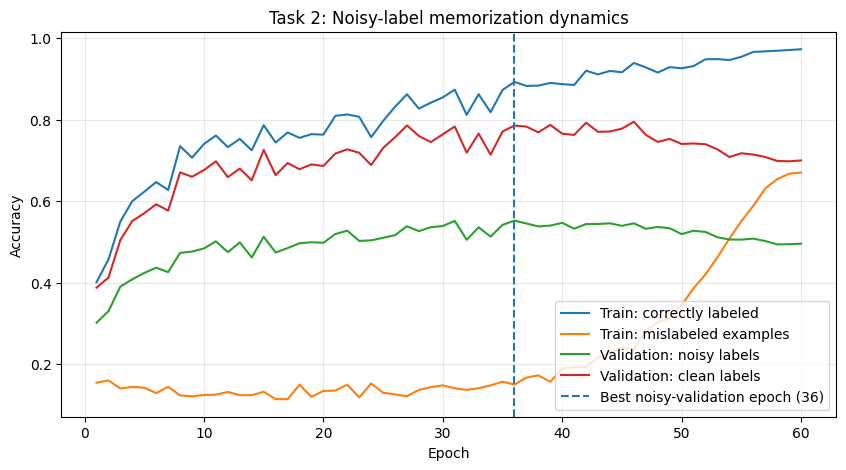

In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/cv_bootcamp/submission"
path = os.path.join(BASE, "predictions", "t2_dynamics.csv")
df = pd.read_csv(path)

print("Top epochs by noisy-label validation accuracy:")
print(
    df.nlargest(10, "val_acc_noisy")[
        ["epoch", "train_acc_correct", "train_acc_mislabeled",
         "val_acc_noisy", "val_acc_clean"]
    ].to_string(index=False)
)

plt.figure(figsize=(10, 5))
plt.plot(df["epoch"], df["train_acc_correct"], label="Train: correctly labeled")
plt.plot(df["epoch"], df["train_acc_mislabeled"], label="Train: mislabeled examples")
plt.plot(df["epoch"], df["val_acc_noisy"], label="Validation: noisy labels")
plt.plot(df["epoch"], df["val_acc_clean"], label="Validation: clean labels")
plt.axvline(36, linestyle="--", label="Best noisy-validation epoch (36)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Task 2: Noisy-label memorization dynamics")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
import json
from pathlib import Path

BASE = Path("/content/drive/MyDrive/cv_bootcamp/submission")
metrics_path = BASE / "task1_2_metrics.json"

with open(metrics_path, "r") as f:
    metrics = json.load(f)

print("Current Task 2 metrics:")
print(json.dumps(metrics["task2"], indent=2))

Current Task 2 metrics:
{
  "memorization_start_epoch": null,
  "early_stop_epoch": 36,
  "val_acc_noisy_labels_at_early_stop": 0.5526
}


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/cv_bootcamp/submission")
df = pd.read_csv(BASE / "predictions" / "t2_dynamics.csv")

# Inspect the dynamics in 5-epoch intervals
print(
    df[df["epoch"] % 5 == 0][
        ["epoch", "train_acc_correct", "train_acc_mislabeled",
         "val_acc_noisy", "val_acc_clean"]
    ].round(4).to_string(index=False)
)

# Find epoch with the highest noisy validation accuracy
best_row = df.loc[df["val_acc_noisy"].idxmax()]
print("\nBest noisy-validation epoch:", int(best_row["epoch"]))
print("Best noisy-validation accuracy:", round(best_row["val_acc_noisy"], 4))

 epoch  train_acc_correct  train_acc_mislabeled  val_acc_noisy  val_acc_clean
     5             0.6236                0.1425         0.4242         0.5708
    10             0.7407                0.1245         0.4844         0.6768
    15             0.7868                0.1326         0.5130         0.7262
    20             0.7637                0.1345         0.4982         0.6868
    25             0.7973                0.1302         0.5104         0.7310
    30             0.8552                0.1483         0.5394         0.7646
    35             0.8733                0.1573         0.5422         0.7714
    40             0.8876                0.1886         0.5472         0.7660
    45             0.9168                0.2402         0.5398         0.7784
    50             0.9265                0.3451         0.5196         0.7408
    55             0.9547                0.5513         0.5060         0.7180
    60             0.9733                0.6707         0.4960  

In [ ]:
import json
from pathlib import Path

BASE = Path("/content/drive/MyDrive/cv_bootcamp/submission")
metrics_path = BASE / "task1_2_metrics.json"

with open(metrics_path, "r") as f:
    metrics = json.load(f)

metrics["task2"]["memorization_start_epoch"] = 40
metrics["task2"]["early_stop_epoch"] = 36
metrics["task2"]["val_acc_noisy_labels_at_early_stop"] = 0.5526

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print("Updated Task 2 metrics:")
print(json.dumps(metrics["task2"], indent=2))

Updated Task 2 metrics:
{
  "memorization_start_epoch": 40,
  "early_stop_epoch": 36,
  "val_acc_noisy_labels_at_early_stop": 0.5526
}


In [ ]:
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

BASE = Path("/content/drive/MyDrive/cv_bootcamp")
SUB = BASE / "submission"
CODE = SUB / "code"
PRED = SUB / "predictions"

sys.path.insert(0, str(CODE))
from model import ResNet18

# Locate dataset files
def find_file(name):
    matches = list(BASE.rglob(name))
    if not matches:
        raise FileNotFoundError(f"Could not find {name} under {BASE}")
    return matches[0]

train_images = np.load(find_file("train_images.npy"))
labels_df = pd.read_csv(find_file("labels.csv"))
train_idx = np.loadtxt(find_file("train_idx.txt"), dtype=int)

# Ensure labels correspond to image indices
labels_df = labels_df.sort_values("index").reset_index(drop=True)
noisy_labels = labels_df["noisy_label"].to_numpy()

# Evaluation transform: no random augmentation
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

class NoiseScoreDataset(Dataset):
    def __init__(self, images, indices, transform):
        self.images = images
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])
        image = Image.fromarray(self.images[idx])
        return self.transform(image), idx

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet18(num_classes=10).to(device)

checkpoint = SUB / "checkpoints" / "t2_early_stop.pt"
if not checkpoint.exists():
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint}")

state = torch.load(checkpoint, map_location=device, weights_only=True)
model.load_state_dict(state)
model.eval()

loader = DataLoader(
    NoiseScoreDataset(train_images, train_idx, transform),
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

all_indices, all_scores = [], []

with torch.no_grad():
    for batch_images, batch_indices in loader:
        batch_images = batch_images.to(device)
        probabilities = F.softmax(model(batch_images), dim=1).cpu().numpy()
        batch_indices_np = batch_indices.numpy()

        # Higher score = model is less confident in the supplied noisy label
        scores = 1.0 - probabilities[
            np.arange(len(batch_indices_np)),
            noisy_labels[batch_indices_np]
        ]

        all_indices.extend(batch_indices_np.tolist())
        all_scores.extend(scores.tolist())

out = pd.DataFrame({
    "index": all_indices,
    "score": all_scores
})
out.to_csv(PRED / "t3_noise_scores.csv", index=False)

print("Saved:", PRED / "t3_noise_scores.csv")
print("Rows:", len(out))
print("Unique indices:", out["index"].nunique())
print("\nHighest-scored examples:")
print(out.nlargest(10, "score").to_string(index=False))

Saved: /content/drive/MyDrive/cv_bootcamp/submission/predictions/t3_noise_scores.csv
Rows: 45000
Unique indices: 45000

Highest-scored examples:
 index    score
 45881 0.998377
  2155 0.997705
 49731 0.997567
 45103 0.997435
  5143 0.997301
 48135 0.997098
 15406 0.996714
 26397 0.996625
  2434 0.996554
  3067 0.996531


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score

BASE = Path("/content/drive/MyDrive/cv_bootcamp")
SUB = BASE / "submission"

def find_file(name):
    matches = list(BASE.rglob(name))
    if not matches:
        raise FileNotFoundError(f"Could not find {name}")
    return matches[0]

scores_df = pd.read_csv(SUB / "predictions" / "t3_noise_scores.csv")
labels_df = pd.read_csv(find_file("labels.csv"))

# Align labels by original dataset index
labels_df = labels_df.set_index("index")
scores_df["clean_label"] = labels_df.loc[
    scores_df["index"], "clean_label"
].to_numpy()
scores_df["noisy_label"] = labels_df.loc[
    scores_df["index"], "noisy_label"
].to_numpy()

# Evaluation target: 1 means the supplied noisy label is incorrect
scores_df["is_mislabeled"] = (
    scores_df["clean_label"] != scores_df["noisy_label"]
).astype(int)

y_true = scores_df["is_mislabeled"].to_numpy()
y_score = scores_df["score"].to_numpy()

k = int(y_true.sum())
auroc = roc_auc_score(y_true, y_score)

top_k = scores_df.nlargest(k, "score")
precision_at_k = top_k["is_mislabeled"].mean()

print("Training examples evaluated:", len(scores_df))
print("Mislabeled examples (k):", k)
print("Mislabeled fraction:", round(y_true.mean(), 4))
print("Noise-detection AUROC:", round(auroc, 4))
print(f"Precision@{k}:", round(precision_at_k, 4))

Training examples evaluated: 45000
Mislabeled examples (k): 18109
Mislabeled fraction: 0.4024
Noise-detection AUROC: 0.9404
Precision@18109: 0.838


In [ ]:
import json
from pathlib import Path

BASE = Path("/content/drive/MyDrive/cv_bootcamp/submission")
metrics_path = BASE / "task1_2_metrics.json"

with open(metrics_path, "r") as f:
    metrics = json.load(f)

metrics["task3"] = {
    "method": "Early-stopped noisy-label CE; score = 1 - P(noisy label)",
    "evaluated_training_examples": 45000,
    "mislabeled_examples": 18109,
    "noise_fraction": 0.4024,
    "noise_detection_auroc": 0.9404,
    "precision_at_k": 0.8380,
    "k": 18109
}

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print("Task 3 metrics saved.")
print(json.dumps(metrics["task3"], indent=2))

Task 3 metrics saved.
{
  "method": "Early-stopped noisy-label CE; score = 1 - P(noisy label)",
  "evaluated_training_examples": 45000,
  "mislabeled_examples": 18109,
  "noise_fraction": 0.4024,
  "noise_detection_auroc": 0.9404,
  "precision_at_k": 0.838,
  "k": 18109
}


In [ ]:
from pathlib import Path

script = Path(
    "/content/drive/MyDrive/cv_bootcamp/submission/code/train_task1_2.py"
)

print("Script exists:", script.exists())

if script.exists():
    lines = script.read_text().splitlines()
    for i, line in enumerate(lines, start=1):
        if any(term in line.lower() for term in [
            "def train", "crossentropyloss", "def evaluate",
            "def main", "argparse", "optimizer", "scheduler"
        ]):
            start = max(1, i - 2)
            end = min(len(lines), i + 4)
            print(f"\n--- Lines {start}-{end} ---")
            for j in range(start, end + 1):
                print(f"{j}: {lines[j-1]}")

Script exists: True

--- Lines 3-9 ---
3: from pathlib import Path
4: import random
5: import argparse
6: import numpy as np
7: import pandas as pd
8: from PIL import Image
9: 

--- Lines 96-102 ---
96: 
97: 
98: def main():
99:     parser = argparse.ArgumentParser()
100:     parser.add_argument("--data-dir", default="/content/drive/MyDrive/cv_bootcamp")
101:     parser.add_argument("--out-dir", default="/content/drive/MyDrive/cv_bootcamp/submission")
102:     parser.add_argument("--epochs", type=int, default=60)

--- Lines 97-103 ---
97: 
98: def main():
99:     parser = argparse.ArgumentParser()
100:     parser.add_argument("--data-dir", default="/content/drive/MyDrive/cv_bootcamp")
101:     parser.add_argument("--out-dir", default="/content/drive/MyDrive/cv_bootcamp/submission")
102:     parser.add_argument("--epochs", type=int, default=60)
103:     parser.add_argument("--batch-size", type=int, default=128)

--- Lines 189-195 ---
189:     )
190:     clean_model = make_model(device)


In [ ]:
%%writefile /content/drive/MyDrive/cv_bootcamp/submission/code/train_task4.py
import os
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from model import ResNet18

BASE = Path("/content/drive/MyDrive/cv_bootcamp")
SUB = BASE / "submission"
PRED = SUB / "predictions"
CKPT = SUB / "checkpoints"

PRED.mkdir(parents=True, exist_ok=True)
CKPT.mkdir(parents=True, exist_ok=True)

SEED = 42
EPOCHS = 60
BATCH_SIZE = 128
LABEL_SMOOTHING = 0.1

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def find_file(name):
    matches = list(BASE.rglob(name))
    if not matches:
        raise FileNotFoundError(f"Cannot find {name} under {BASE}")
    return matches[0]

class CIFARData(Dataset):
    def __init__(self, images, indices, labels=None, training=False):
        self.images = images
        self.indices = np.asarray(indices, dtype=int)
        self.labels = labels
        self.transform = transforms.Compose([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(
                (0.4914, 0.4822, 0.4465),
                (0.2470, 0.2435, 0.2616)
            )
        ]) if training else transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(
                (0.4914, 0.4822, 0.4465),
                (0.2470, 0.2435, 0.2616)
            )
        ])

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])
        x = self.transform(Image.fromarray(self.images[idx]))
        if self.labels is None:
            return x, idx
        return x, int(self.labels[idx])

def main():
    seed_everything(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)
    if device.type == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))

    train_images = np.load(find_file("train_images.npy"))
    test_images = np.load(find_file("test_images.npy"))
    labels_df = pd.read_csv(find_file("labels.csv"))
    labels_df = labels_df.sort_values("index").reset_index(drop=True)

    # Task 4 uses noisy labels only; clean labels are not loaded or used.
    noisy_labels = labels_df["noisy_label"].to_numpy()
    train_idx = np.loadtxt(find_file("train_idx.txt"), dtype=int)
    val_idx = np.loadtxt(find_file("val_idx.txt"), dtype=int)

    train_ds = CIFARData(train_images, train_idx, noisy_labels, training=True)
    val_ds = CIFARData(train_images, val_idx, noisy_labels, training=False)
    test_ds = CIFARData(test_images, np.arange(len(test_images)), training=False)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=2, pin_memory=(device.type == "cuda")
    )
    val_loader = DataLoader(
        val_ds, batch_size=256, shuffle=False,
        num_workers=2, pin_memory=(device.type == "cuda")
    )
    test_loader = DataLoader(
        test_ds, batch_size=256, shuffle=False,
        num_workers=2, pin_memory=(device.type == "cuda")
    )

    model = ResNet18(num_classes=10).to(device)
    optimizer = torch.optim.SGD(
        model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

    best_val_acc = -1.0
    best_epoch = 0
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total, correct, total_loss = 0, 0, 0.0

        for x, y in train_loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)

        scheduler.step()

        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                pred = model(x).argmax(1)
                val_correct += (pred == y).sum().item()
                val_total += y.size(0)

        train_acc = correct / total
        val_acc = val_correct / val_total
        avg_loss = total_loss / total

        history.append({
            "epoch": epoch,
            "train_loss": avg_loss,
            "train_acc_noisy": train_acc,
            "val_acc_noisy": val_acc
        })

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"loss={avg_loss:.4f} | train_acc={train_acc:.4f} | "
            f"val_acc_noisy={val_acc:.4f}",
            flush=True
        )

        # Select checkpoint using noisy-label validation accuracy only.
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            torch.save(
                model.state_dict(),
                CKPT / "t4_label_smoothing_best.pt"
            )

        torch.save(
            model.state_dict(),
            CKPT / "t4_label_smoothing_latest.pt"
        )

    pd.DataFrame(history).to_csv(
        PRED / "t4_label_smoothing_dynamics.csv", index=False
    )

    # Predict test labels using the best noisy-validation checkpoint.
    best_model = ResNet18(num_classes=10).to(device)
    best_model.load_state_dict(torch.load(
        CKPT / "t4_label_smoothing_best.pt",
        map_location=device,
        weights_only=True
    ))
    best_model.eval()

    ids, predictions = [], []
    with torch.no_grad():
        for x, batch_ids in test_loader:
            x = x.to(device, non_blocking=True)
            pred = best_model(x).argmax(1).cpu().numpy()
            ids.extend(batch_ids.numpy().tolist())
            predictions.extend(pred.tolist())

    pd.DataFrame({"id": ids, "pred": predictions}).to_csv(
        PRED / "t4_label_smoothing.csv", index=False
    )

    result = {
        "method": "label_smoothing",
        "label_smoothing": LABEL_SMOOTHING,
        "epochs_trained": EPOCHS,
        "best_epoch": best_epoch,
        "best_val_acc_noisy": best_val_acc,
        "selection_metric": "noisy_label_validation_accuracy",
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "optimizer": "SGD(momentum=0.9, weight_decay=5e-4)",
        "learning_rate": 0.1,
        "scheduler": "CosineAnnealingLR",
        "architecture": "organizer ResNet-18 trained from scratch"
    }

    with open(SUB / "task4_metrics.json", "w") as f:
        json.dump(result, f, indent=2)

    print("\nTask 4 training complete.")
    print(json.dumps(result, indent=2))
    print("Predictions:", PRED / "t4_label_smoothing.csv")

if __name__ == "__main__":
    main()

Writing /content/drive/MyDrive/cv_bootcamp/submission/code/train_task4.py


In [ ]:
%cd /content/drive/MyDrive/cv_bootcamp/submission/code

!python -u train_task4.py

/content/drive/MyDrive/cv_bootcamp/submission/code
Device: cuda
GPU: Tesla T4
Epoch 01/60 | loss=2.2394 | train_acc=0.2155 | val_acc_noisy=0.2872
Epoch 02/60 | loss=2.0150 | train_acc=0.2961 | val_acc_noisy=0.3016
Epoch 03/60 | loss=1.9447 | train_acc=0.3473 | val_acc_noisy=0.3282
Epoch 04/60 | loss=1.8923 | train_acc=0.3780 | val_acc_noisy=0.3834
Epoch 05/60 | loss=1.8525 | train_acc=0.4018 | val_acc_noisy=0.3870
Epoch 06/60 | loss=1.8148 | train_acc=0.4284 | val_acc_noisy=0.4102
Epoch 07/60 | loss=1.7839 | train_acc=0.4469 | val_acc_noisy=0.4076
Epoch 08/60 | loss=1.7582 | train_acc=0.4612 | val_acc_noisy=0.4432
Epoch 09/60 | loss=1.7321 | train_acc=0.4776 | val_acc_noisy=0.4748
Epoch 10/60 | loss=1.7097 | train_acc=0.4918 | val_acc_noisy=0.4854
Epoch 11/60 | loss=1.6916 | train_acc=0.5035 | val_acc_noisy=0.5062
Epoch 12/60 | loss=1.6815 | train_acc=0.5111 | val_acc_noisy=0.4774
Epoch 13/60 | loss=1.6724 | train_acc=0.5158 | val_acc_noisy=0.4848
Epoch 14/60 | loss=1.6632 | train_acc=

In [ ]:

from pathlib import Path

script = r'''import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from model import ResNet18

BASE = Path("/content/drive/MyDrive/cv_bootcamp")
SUB = BASE / "submission"
PRED = SUB / "predictions"
CKPT = SUB / "checkpoints"
PRED.mkdir(parents=True, exist_ok=True)
CKPT.mkdir(parents=True, exist_ok=True)

SEED = 42
EPOCHS = 60
BATCH_SIZE = 128

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def find_file(name):
    matches = list(BASE.rglob(name))
    if not matches:
        raise FileNotFoundError(f"Cannot find {name} under {BASE}")
    return matches[0]

class CIFARData(Dataset):
    def __init__(self, images, indices, labels, training=False):
        self.images = images
        self.indices = np.asarray(indices, dtype=int)
        self.labels = labels
        if training:
            self.transform = transforms.Compose([
                transforms.RandomCrop(32, padding=4),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor(),
                transforms.Normalize(
                    (0.4914, 0.4822, 0.4465),
                    (0.2470, 0.2435, 0.2616)
                )
            ])
        else:
            self.transform = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize(
                    (0.4914, 0.4822, 0.4465),
                    (0.2470, 0.2435, 0.2616)
                )
            ])

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])
        image = Image.fromarray(self.images[idx])
        return self.transform(image), int(self.labels[idx])

def run_method(name, smoothing, train_images, test_images,
               labels, train_idx, val_idx, device):
    print(f"\n===== Training {name} =====", flush=True)

    # Reset seed so both methods use the same initialization and shuffle seed.
    seed_everything(SEED)

    train_ds = CIFARData(train_images, train_idx, labels, training=True)
    val_ds = CIFARData(train_images, val_idx, labels, training=False)
    test_ds = CIFARData(
        test_images, np.arange(len(test_images)),
        np.zeros(len(test_images), dtype=int), training=False
    )

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=2, pin_memory=(device.type == "cuda")
    )
    val_loader = DataLoader(
        val_ds, batch_size=256, shuffle=False,
        num_workers=2, pin_memory=(device.type == "cuda")
    )
    test_loader = DataLoader(
        test_ds, batch_size=256, shuffle=False,
        num_workers=2, pin_memory=(device.type == "cuda")
    )

    model = ResNet18(num_classes=10).to(device)
    optimizer = torch.optim.SGD(
        model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

    best_val = -1.0
    best_epoch = 0
    history = []
    checkpoint_path = CKPT / f"{name}_best.pt"

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total, correct, total_loss = 0, 0, 0.0

        for x, y in train_loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)

        scheduler.step()
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                val_correct += (model(x).argmax(1) == y).sum().item()
                val_total += y.size(0)

        val_acc = val_correct / val_total
        history.append({
            "epoch": epoch,
            "train_loss": total_loss / total,
            "train_acc_synthetic": correct / total,
            "val_acc_synthetic": val_acc
        })

        print(
            f"{name} epoch {epoch:02d}/{EPOCHS} "
            f"train_acc={correct/total:.4f} val_acc={val_acc:.4f}",
            flush=True
        )

        if val_acc > best_val:
            best_val = val_acc
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint_path)

    pd.DataFrame(history).to_csv(
        PRED / f"{name}_dynamics.csv", index=False
    )

    best_model = ResNet18(num_classes=10).to(device)
    best_model.load_state_dict(torch.load(
        checkpoint_path, map_location=device, weights_only=True
    ))
    best_model.eval()

    ids, predictions = [], []
    with torch.no_grad():
        for batch_num, (x, _) in enumerate(test_loader):
            x = x.to(device, non_blocking=True)
            pred = best_model(x).argmax(1).cpu().numpy()
            start = batch_num * 256
            ids.extend(range(start, start + len(pred)))
            predictions.extend(pred.tolist())

    filename = (
        "t5_baseline_synth.csv" if smoothing == 0
        else "t5_best_synth.csv"
    )
    pd.DataFrame({"id": ids, "pred": predictions}).to_csv(
        PRED / filename, index=False
    )

    result = {
        "method": name,
        "label_smoothing": smoothing,
        "epochs_trained": EPOCHS,
        "best_epoch": best_epoch,
        "best_val_acc_synthetic": best_val,
        "selection_metric": "synthetic_label_validation_accuracy",
        "seed": SEED,
        "batch_size": BATCH_SIZE
    }
    print("Result:", json.dumps(result), flush=True)
    return result

def main():
    seed_everything(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)
    if device.type == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))

    train_images = np.load(find_file("train_images.npy"))
    test_images = np.load(find_file("test_images.npy"))
    labels_df = pd.read_csv(find_file("labels.csv"))
    labels_df = labels_df.sort_values("index").reset_index(drop=True)

    # Task 5 uses synthetic labels only.
    synthetic_labels = labels_df["synthetic_label"].to_numpy()
    train_idx = np.loadtxt(find_file("train_idx.txt"), dtype=int)
    val_idx = np.loadtxt(find_file("val_idx.txt"), dtype=int)

    baseline = run_method(
        "t5_baseline_ce", 0.0, train_images, test_images,
        synthetic_labels, train_idx, val_idx, device
    )
    robust = run_method(
        "t5_label_smoothing", 0.1, train_images, test_images,
        synthetic_labels, train_idx, val_idx, device
    )

    results = {"baseline": baseline, "best_robust_method": robust}
    with open(SUB / "task5_metrics.json", "w") as f:
        json.dump(results, f, indent=2)

    print("\nTask 5 complete.")
    print(json.dumps(results, indent=2))

if __name__ == "__main__":
    main()
'''

path = Path("/content/drive/MyDrive/cv_bootcamp/submission/code/train_task5.py")
path.write_text(script)
print("Created:", path)


Created: /content/drive/MyDrive/cv_bootcamp/submission/code/train_task5.py


In [ ]:
%cd /content/drive/MyDrive/cv_bootcamp/submission/code
!python -u train_task5.py

/content/drive/MyDrive/cv_bootcamp/submission/code
Device: cuda
GPU: Tesla T4

===== Training t5_baseline_ce =====
t5_baseline_ce epoch 01/60 train_acc=0.1716 val_acc=0.2204
t5_baseline_ce epoch 02/60 train_acc=0.2317 val_acc=0.2622
t5_baseline_ce epoch 03/60 train_acc=0.2670 val_acc=0.2774
t5_baseline_ce epoch 04/60 train_acc=0.2913 val_acc=0.2978
t5_baseline_ce epoch 05/60 train_acc=0.3091 val_acc=0.3024
t5_baseline_ce epoch 06/60 train_acc=0.3322 val_acc=0.3428
t5_baseline_ce epoch 07/60 train_acc=0.3564 val_acc=0.3178
t5_baseline_ce epoch 08/60 train_acc=0.3741 val_acc=0.3822
t5_baseline_ce epoch 09/60 train_acc=0.3886 val_acc=0.3578
t5_baseline_ce epoch 10/60 train_acc=0.4012 val_acc=0.3912
t5_baseline_ce epoch 11/60 train_acc=0.4136 val_acc=0.3678
t5_baseline_ce epoch 12/60 train_acc=0.4199 val_acc=0.4194
t5_baseline_ce epoch 13/60 train_acc=0.4274 val_acc=0.4014
t5_baseline_ce epoch 14/60 train_acc=0.4352 val_acc=0.4190
t5_baseline_ce epoch 15/60 train_acc=0.4462 val_acc=0.3722


In [3]:
from pathlib import Path
import pandas as pd

SUB = Path("/content/drive/MyDrive/cv_bootcamp/submission")
PRED = SUB / "predictions"
CKPT = SUB / "checkpoints"

files_to_check = [
    PRED / "t5_baseline_synth.csv",
    PRED / "t5_baseline_ce_dynamics.csv",
    PRED / "t5_label_smoothing.csv",
    PRED / "t5_label_smoothing_dynamics.csv",
    CKPT / "t5_baseline_ce_best.pt",
    CKPT / "t5_label_smoothing_best.pt",
]

for path in files_to_check:
    print(f"{'EXISTS' if path.exists() else 'MISSING'}: {path.name}")

baseline_dynamics = PRED / "t5_baseline_ce_dynamics.csv"
if baseline_dynamics.exists():
    df = pd.read_csv(baseline_dynamics)
    best = df.loc[df["val_acc_synthetic"].idxmax()]
    print("\nBaseline best epoch:", int(best["epoch"]))
    print("Baseline best synthetic validation accuracy:",
          round(best["val_acc_synthetic"], 4))

EXISTS: t5_baseline_synth.csv
EXISTS: t5_baseline_ce_dynamics.csv
MISSING: t5_label_smoothing.csv
MISSING: t5_label_smoothing_dynamics.csv
EXISTS: t5_baseline_ce_best.pt
EXISTS: t5_label_smoothing_best.pt

Baseline best epoch: 45
Baseline best synthetic validation accuracy: 0.499


In [6]:

# TASK 5: Restart label smoothing from scratch, with resumable checkpoints

import os, sys, json, random, inspect
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

ROOT = "/content/drive/MyDrive/cv_bootcamp"
DATA_ROOT = f"{ROOT}/data"
SUB = f"{ROOT}/submission"
CODE = f"{SUB}/code"
PRED = f"{SUB}/predictions"
CKPT = f"{SUB}/checkpoints"

for folder in [CODE, PRED, CKPT]:
    os.makedirs(folder, exist_ok=True)

sys.path.insert(0, CODE)
sys.path.insert(0, ROOT)

# Use only the synthetic labels for this task.
SEED = 42
EPOCHS = 60
BATCH_SIZE = 128
LR = 0.1
SMOOTHING = 0.1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
assert device.type == "cuda", "Enable a GPU runtime before training."

# Load data
train_images = np.load(f"{DATA_ROOT}/train_images.npy")
test_images = np.load(f"{DATA_ROOT}/test_images.npy")
labels_df = pd.read_csv(f"{DATA_ROOT}/labels.csv")

train_idx = np.loadtxt(f"{DATA_ROOT}/train_idx.txt", dtype=int)
val_idx = np.loadtxt(f"{DATA_ROOT}/val_idx.txt", dtype=int)

synthetic_labels = labels_df["synthetic_label"].to_numpy().astype(np.int64)

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class CIFARArrayDataset(Dataset):
    def __init__(self, images, indices, labels=None, train=False):
        self.images = images
        self.indices = np.asarray(indices)
        self.labels = labels
        self.transform = train_tf if train else eval_tf

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])
        image = self.images[idx]
        # Convert RGB array to PIL for torchvision transforms
        from PIL import Image
        image = Image.fromarray(image)
        x = self.transform(image)
        if self.labels is None:
            return x, idx
        return x, int(self.labels[idx])

train_ds = CIFARArrayDataset(
    train_images, train_idx, synthetic_labels, train=True
)
val_ds = CIFARArrayDataset(
    train_images, val_idx, synthetic_labels, train=False
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=256, shuffle=False,
    num_workers=2, pin_memory=True
)

# Import the organizer-provided model; do not use pretrained weights.
import model as organizer_model

print("Model module:", organizer_model.__file__)
print("Available model classes:",
      [n for n, obj in inspect.getmembers(organizer_model, inspect.isclass)
       if issubclass(obj, nn.Module) and obj is not nn.Module])

# Adjust this constructor if your model.py uses a different class name.
if hasattr(organizer_model, "ResNet18"):
    net = organizer_model.ResNet18()
elif hasattr(organizer_model, "ResNet"):
    net = organizer_model.ResNet()
else:
    raise RuntimeError(
        "Could not identify the organizer model constructor. "
        "Check the printed class names and model.py before training."
    )

net = net.to(device)

# Verify that this is a fresh initialization, not a saved checkpoint.
print("Trainable parameters:", sum(p.numel() for p in net.parameters()
                                   if p.requires_grad))

criterion = nn.CrossEntropyLoss(label_smoothing=SMOOTHING)
optimizer = torch.optim.SGD(
    net.parameters(), lr=LR, momentum=0.9, weight_decay=5e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS
)

BEST_PATH = f"{CKPT}/t5_label_smoothing_best.pt"
LATEST_PATH = f"{CKPT}/t5_label_smoothing_latest_resume.pt"
DYNAMICS_PATH = f"{PRED}/t5_label_smoothing_dynamics.csv"
PRED_PATH = f"{PRED}/t5_best_synth.csv"
METRICS_PATH = f"{SUB}/task5_label_smoothing_metrics.json"

# Remove only outputs from the interrupted label-smoothing run.
# The Task 5 baseline and all Task 1–4 files are left untouched.
for path in [BEST_PATH, LATEST_PATH, DYNAMICS_PATH, PRED_PATH, METRICS_PATH]:
    if os.path.exists(path):
        os.remove(path)

history = []
best_val = -1.0
best_epoch = 0

def evaluate(model, loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)
    return correct / total

for epoch in range(1, EPOCHS + 1):
    net.train()
    total_loss = total_correct = total_seen = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = net(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * y.size(0)
        total_correct += (logits.argmax(1) == y).sum().item()
        total_seen += y.size(0)

    train_loss = total_loss / total_seen
    train_acc = total_correct / total_seen
    val_acc = evaluate(net, val_loader)
    scheduler.step()

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_acc_synthetic": val_acc,
        "learning_rate_next": optimizer.param_groups[0]["lr"],
    }
    history.append(row)

    if val_acc > best_val:
        best_val = val_acc
        best_epoch = epoch
        torch.save(net.state_dict(), BEST_PATH)

    # Save progress after every completed epoch for recovery.
    torch.save({
        "epoch": epoch,
        "model_state_dict": net.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val": best_val,
        "best_epoch": best_epoch,
        "history": history,
    }, LATEST_PATH)

    pd.DataFrame(history).to_csv(DYNAMICS_PATH, index=False)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
        f"synthetic_val_acc={val_acc:.4f} | best={best_val:.4f} "
        f"(epoch {best_epoch})",
        flush=True
    )

# Predict test set using the best synthetic-validation checkpoint.
net.load_state_dict(torch.load(BEST_PATH, map_location=device))
net.eval()

test_ds = CIFARArrayDataset(
    test_images, np.arange(len(test_images)), labels=None, train=False
)
test_loader = DataLoader(
    test_ds, batch_size=256, shuffle=False,
    num_workers=2, pin_memory=True
)

preds, ids = [], []
with torch.no_grad():
    for x, batch_ids in test_loader:
        x = x.to(device)
        preds.extend(net(x).argmax(1).cpu().numpy().tolist())
        ids.extend(batch_ids.numpy().tolist())

pd.DataFrame({"id": ids, "pred": preds}).to_csv(PRED_PATH, index=False)

metrics = {
    "method": "label_smoothing",
    "label_smoothing": SMOOTHING,
    "epochs_trained": EPOCHS,
    "best_epoch": best_epoch,
    "best_val_acc_synthetic": best_val,
    "selection_metric": "synthetic-label validation accuracy",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "optimizer": "SGD(momentum=0.9, weight_decay=5e-4)",
    "learning_rate": LR,
    "scheduler": "CosineAnnealingLR(T_max=60)",
    "architecture": "organizer ResNet-18 trained from scratch",
    "checkpointing": "model, optimizer, scheduler and history saved each epoch",
}

with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)

print("\nTASK 5 LABEL-SMOOTHING RUN COMPLETE")
print("Best epoch:", best_epoch)
print("Best synthetic validation accuracy:", round(best_val, 4))
print("Predictions:", PRED_PATH)
print("Dynamics:", DYNAMICS_PATH)
print("Metrics:", METRICS_PATH)


Device: cuda
Model module: /content/drive/MyDrive/cv_bootcamp/model.py
Available model classes: ['BasicBlock', 'ResNet']
Trainable parameters: 11173962
Epoch 01/60 | loss=2.3641 | train_acc=0.1586 | synthetic_val_acc=0.2068 | best=0.2068 (epoch 1)
Epoch 02/60 | loss=2.1904 | train_acc=0.2251 | synthetic_val_acc=0.2442 | best=0.2442 (epoch 2)
Epoch 03/60 | loss=2.1550 | train_acc=0.2556 | synthetic_val_acc=0.2642 | best=0.2642 (epoch 3)
Epoch 04/60 | loss=2.1251 | train_acc=0.2792 | synthetic_val_acc=0.2900 | best=0.2900 (epoch 4)
Epoch 05/60 | loss=2.0994 | train_acc=0.2982 | synthetic_val_acc=0.3076 | best=0.3076 (epoch 5)
Epoch 06/60 | loss=2.0762 | train_acc=0.3210 | synthetic_val_acc=0.3152 | best=0.3152 (epoch 6)
Epoch 07/60 | loss=2.0508 | train_acc=0.3418 | synthetic_val_acc=0.3346 | best=0.3346 (epoch 7)
Epoch 08/60 | loss=2.0246 | train_acc=0.3612 | synthetic_val_acc=0.3742 | best=0.3742 (epoch 8)
Epoch 09/60 | loss=2.0022 | train_acc=0.3795 | synthetic_val_acc=0.3558 | best=0

In [3]:
import os
import json
import pandas as pd

ROOT = "/content/drive/MyDrive/cv_bootcamp"
SUB = f"{ROOT}/submission"
PRED = f"{SUB}/predictions"
CKPT = f"{SUB}/checkpoints"

required_files = [
    f"{PRED}/t1_clean_ref.csv",
    f"{PRED}/t1_noisy_ce.csv",
    f"{PRED}/t2_early_stop.csv",
    f"{PRED}/t2_dynamics.csv",
    f"{PRED}/t3_noise_scores.csv",
    f"{PRED}/t4_label_smoothing.csv",
    f"{PRED}/t5_baseline_synth.csv",
    f"{PRED}/t5_best_synth.csv",
    f"{PRED}/t5_label_smoothing_dynamics.csv",
    f"{SUB}/task1_2_metrics.json",
    f"{SUB}/task4_metrics.json",
    f"{SUB}/task5_label_smoothing_metrics.json",
    f"{SUB}/code/model.py",
    f"{SUB}/code/check_format.py",
]

print("=== FILE CHECK ===")
for path in required_files:
    print(("OK      " if os.path.exists(path) else "MISSING "), path)

print("\n=== TEST PREDICTION SHAPES ===")
for name in [
    "t1_clean_ref.csv",
    "t1_noisy_ce.csv",
    "t2_early_stop.csv",
    "t4_label_smoothing.csv",
    "t5_baseline_synth.csv",
    "t5_best_synth.csv",
]:
    path = f"{PRED}/{name}"
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(name, "| rows:", len(df), "| columns:", list(df.columns))

print("\n=== TASK 5 METRICS ===")
for path in [
    f"{SUB}/task5_label_smoothing_metrics.json",
    f"{SUB}/task1_2_metrics.json",
    f"{SUB}/task4_metrics.json",
]:
    if os.path.exists(path):
        with open(path) as f:
            print(os.path.basename(path), json.load(f))

=== FILE CHECK ===
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t1_clean_ref.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t1_noisy_ce.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t2_early_stop.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t2_dynamics.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t3_noise_scores.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t4_label_smoothing.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t5_baseline_synth.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t5_best_synth.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/predictions/t5_label_smoothing_dynamics.csv
OK       /content/drive/MyDrive/cv_bootcamp/submission/task1_2_metrics.json
OK       /content/drive/MyDrive/cv_bootcamp/submission/task4_metrics.json
OK       /content/drive/MyDrive/cv_bootcamp/su

In [4]:
import os
import json

ROOT = "/content/drive/MyDrive/cv_bootcamp"
SUB = f"{ROOT}/submission"

print("=== SUBMISSION FILES ===")
for folder in ["code", "predictions", "checkpoints"]:
    path = os.path.join(SUB, folder)
    print(f"\n{folder}/")
    if os.path.exists(path):
        for name in sorted(os.listdir(path)):
            full = os.path.join(path, name)
            if os.path.isfile(full):
                print(f"  {name} ({os.path.getsize(full):,} bytes)")
            elif folder != "checkpoints":
                print(f"  {name}/")
    else:
        print("  MISSING FOLDER")

print("\n=== RESULTS TEMPLATE ===")
for path in [
    f"{ROOT}/results_template.json",
    f"{ROOT}/data/results_template.json",
    f"{SUB}/results_template.json",
]:
    if os.path.exists(path):
        print("Found:", path)
        with open(path) as f:
            print(json.dumps(json.load(f), indent=2))
        break
else:
    print("No results_template.json found in the checked locations.")

print("\n=== FORMAT CHECKER USAGE ===")
checker = f"{SUB}/code/check_format.py"
if os.path.exists(checker):
    with open(checker, encoding="utf-8") as f:
        print(f.read())
else:
    print("check_format.py not found.")

=== SUBMISSION FILES ===

code/
  __pycache__/
  check_format.py (16,063 bytes)
  data/
  model.py (2,542 bytes)
  train_task1_2.py (13,401 bytes)
  train_task4.py (7,148 bytes)
  train_task5.py (7,302 bytes)

predictions/
  t1_clean_ref.csv (68,898 bytes)
  t1_noisy_ce.csv (68,898 bytes)
  t2_dynamics.csv (3,369 bytes)
  t2_early_stop.csv (68,898 bytes)
  t3_noise_scores.csv (1,123,633 bytes)
  t4_label_smoothing.csv (68,898 bytes)
  t4_label_smoothing_dynamics.csv (2,855 bytes)
  t5_baseline_ce_dynamics.csv (2,772 bytes)
  t5_baseline_synth.csv (68,898 bytes)
  t5_best_synth.csv (68,898 bytes)
  t5_label_smoothing_dynamics.csv (4,042 bytes)

checkpoints/
  t1_clean_ref_final.pt (44,776,203 bytes)
  t1_clean_ref_latest.pt (89,492,087 bytes)
  t1_noisy_ce_final.pt (44,776,075 bytes)
  t2_early_stop.pt (44,775,563 bytes)
  t2_noisy_latest.pt (89,491,327 bytes)
  t4_label_smoothing_best.pt (44,776,971 bytes)
  t4_label_smoothing_latest.pt (44,777,227 bytes)
  t5_baseline_ce_best.pt (44,7

In [5]:

import os
import json
import zipfile
import subprocess
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/cv_bootcamp")
SUB = ROOT / "submission"
PRED = SUB / "predictions"
CODE = SUB / "code"

# Confirm the required existing files before changing anything.
required = [
    PRED / "t1_clean_ref.csv",
    PRED / "t1_noisy_ce.csv",
    PRED / "t2_early_stop.csv",
    PRED / "t2_dynamics.csv",
    PRED / "t3_noise_scores.csv",
    PRED / "t4_label_smoothing.csv",
    PRED / "t5_baseline_synth.csv",
    PRED / "t5_best_synth.csv",
    CODE / "model.py",
    CODE / "check_format.py",
]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Required files missing:\n" + "\n".join(missing))

name = input("Enter your name as required for submission: ").strip()
roll_no = input("Enter your roll number (for the ZIP filename too): ").strip()

if not name or not roll_no:
    raise ValueError("Name and roll number cannot be blank.")

# Official results template structure, populated with measured results.
results = {
    "name": name,
    "roll_no": roll_no,
    "seed": 42,
    "training_setup": {
        "optimizer": "SGD(momentum=0.9, weight_decay=5e-4)",
        "learning_rate_schedule": "CosineAnnealingLR(T_max=60)",
        "batch_size": 128,
        "epochs": 60,
        "augmentation": "RandomCrop(32, padding=4), RandomHorizontalFlip",
        "gpu_used": "Tesla T4"
    },
    "task1": {
        "noise_rate": 40.21,
        "val_acc_noisy_labels__clean_ref_model": 0.595,
        "val_acc_noisy_labels__noisy_ce_model": 0.496
    },
    "task2": {
        "memorization_start_epoch": 40,
        "early_stop_epoch": 36,
        "val_acc_noisy_labels_at_early_stop": 0.5526
    },
    "task3": {
        "method": (
            "Early-stopped noisy-label cross-entropy model; "
            "noise score = 1 - probability assigned to the observed noisy label. "
            "AUROC=0.9404; Precision@k=0.838, k=18109."
        )
    },
    "task4": {
        "methods": [
            {
                "name": "label_smoothing",
                "file": "t4_label_smoothing.csv",
                "val_acc_noisy_labels": 0.5552
            }
        ],
        "best_method": "label_smoothing"
    },
    "task5": {
        "val_acc_synthetic_labels__baseline": 0.499,
        "val_acc_synthetic_labels__best_method": 0.499
    }
}

with open(SUB / "results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

report = """# CV Bootcamp Report

## Q1
The observed noisy labels differ from the clean labels in 40.21% of the full training set. The clean-reference model achieved 59.50% validation accuracy against noisy labels, while the noisy-label cross-entropy model achieved 49.60%. The clean-reference model's accuracy against clean validation labels was 94.46%.

## Q2
The noisy-label model achieved its best noisy-validation accuracy of 55.26% at epoch 36, which was selected for early stopping using noisy-label validation accuracy. The training dynamics suggest memorization begins around epoch 40 and becomes more pronounced later, as training accuracy on mislabeled examples rises while validation performance eventually declines.

## Q3
Noise scores were computed as one minus the model probability assigned to each example's observed noisy label. Higher scores indicate examples the model considers less compatible with their observed labels. Evaluation against clean labels gave AUROC 0.9404 and Precision@k 0.838 for k=18,109. Clean labels were used for evaluation, not to produce the scores.

## Q4
Label smoothing with smoothing factor 0.1 achieved 55.52% noisy-label validation accuracy at epoch 37, compared with 55.26% for the early-stopped cross-entropy baseline. This is an absolute improvement of 0.26 percentage points on the noisy-label validation metric. The model used the organizer-provided ResNet-18 architecture and was trained from scratch.

## Q5
On synthetic-label validation data, the baseline cross-entropy model and label-smoothing model both achieved 49.90% accuracy. Thus, neither method outperformed the other on the reported selection metric. The reported predictions were generated by the corresponding synthetic-label training runs, with label smoothing selected as the tied best method.
"""
(SUB / "report.md").write_text(report, encoding="utf-8")

readme = """# CV Bootcamp Submission

## Contents
- `predictions/`: required test predictions, training dynamics, and noise scores.
- `results.json`: experiment configuration and validation results.
- `report.md`: concise answers for Q1–Q5.
- `code/`: organizer model, format checker, and training scripts.

## Environment
Python with PyTorch, NumPy, pandas, and Pillow; GPU used for the reported runs: Tesla T4.
The data files are located in `../data/` relative to the `cv_bootcamp` root.
The scripts used during development may contain Colab Drive paths; update their path arguments/defaults if running elsewhere.

## Reproduction commands (Google Colab)
Mount Google Drive first, then run:

```bash
python /content/drive/MyDrive/cv_bootcamp/submission/code/train_task1_2.py
python /content/drive/MyDrive/cv_bootcamp/submission/code/train_task4.py
python /content/drive/MyDrive/cv_bootcamp/submission/code/train_task5.py
```

Task 3 scores were computed from the Task 2 early-stopped model using:
`score = 1 - P(observed noisy label | image)`.
The saved score file is `predictions/t3_noise_scores.csv`. Clean labels were used only for evaluation of noise detection, not for scoring.

## Validation
From Google Colab, run the format checker against the submission folder:

```bash
python /content/drive/MyDrive/cv_bootcamp/submission/code/check_format.py /content/drive/MyDrive/cv_bootcamp/submission
```

The checker verifies required filenames and formats; it does not evaluate model quality.
"""
(CODE / "README.md").write_text(readme, encoding="utf-8")

# Package only submission artifacts, not large checkpoints.
zip_path = ROOT / f"{roll_no}_cv_bootcamp.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for folder in ["code", "predictions"]:
        base = SUB / folder
        for path in base.rglob("*"):
            if not path.is_file() or "__pycache__" in path.parts:
                continue
            arcname = path.relative_to(SUB).as_posix()
            z.write(path, arcname)
    for filename in ["results.json", "report.md"]:
        path = SUB / filename
        z.write(path, filename)

print("\nCreated:")
print(" -", SUB / "results.json")
print(" -", SUB / "report.md")
print(" -", CODE / "README.md")
print(" -", zip_path)

# Run the official format checker on the folder and then the ZIP.
checker = CODE / "check_format.py"
print("\n========== CHECK SUBMISSION FOLDER ==========")
folder_check = subprocess.run(
    ["python", str(checker), str(SUB)],
    capture_output=True, text=True
)
print(folder_check.stdout)
if folder_check.stderr:
    print(folder_check.stderr)

print("\n========== CHECK ZIP ==========")
zip_check = subprocess.run(
    ["python", str(checker), str(zip_path)],
    capture_output=True, text=True
)
print(zip_check.stdout)
if zip_check.stderr:
    print(zip_check.stderr)

print("\nZIP size:", f"{zip_path.stat().st_size:,} bytes")


Enter your name as required for submission: Mehak
Enter your roll number (for the ZIP filename too): 23B4210

Created:
 - /content/drive/MyDrive/cv_bootcamp/submission/results.json
 - /content/drive/MyDrive/cv_bootcamp/submission/report.md
 - /content/drive/MyDrive/cv_bootcamp/submission/code/README.md
 - /content/drive/MyDrive/cv_bootcamp/23B4210_cv_bootcamp.zip

========== CHECK SUBMISSION FOLDER ==========

File check
------------------------------------------------------------
  t1_clean_ref.csv           OK
  t1_noisy_ce.csv            OK
  t2_dynamics.csv            OK
  t2_early_stop.csv          OK
  t3_noise_scores.csv        OK
  t4_label_smoothing.csv     OK
  t4_label_smoothing_dynamics.csv INVALID: header must be 'id,pred'
  t5_baseline_synth.csv      OK
  t5_best_synth.csv          OK

Task completeness (1.0 = all files valid)
------------------------------------------------------------
  task1: 1.00
  task2: 1.00
  task3: 1.00
  task4: 0.00
  task5: 1.00

Other issues
--

In [6]:

from pathlib import Path
import os
import zipfile
import subprocess
import sys

ROOT = Path("/content/drive/MyDrive/cv_bootcamp")
SUB = ROOT / "submission"
PRED = SUB / "predictions"
CODE = SUB / "code"
ZIP_PATH = ROOT / "23B4210_cv_bootcamp.zip"
CHECKER = CODE / "check_format.py"

# 1. Remove the optional dynamics file that the checker mistakes for predictions
extra_file = PRED / "t4_label_smoothing_dynamics.csv"
if extra_file.exists():
    extra_file.unlink()
    print("Removed extra file:", extra_file.name)
else:
    print("Extra Task 4 dynamics file is already absent.")

# 2. Rebuild ZIP with the required submission contents only
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["code", "predictions"]:
        folder_path = SUB / folder
        for path in folder_path.rglob("*"):
            if not path.is_file():
                continue
            if "__pycache__" in path.parts:
                continue
            if folder == "code" and path.suffix == ".pyc":
                continue
            zf.write(path, path.relative_to(SUB))

    for filename in ["results.json", "report.md"]:
        path = SUB / filename
        if path.exists():
            zf.write(path, path.relative_to(SUB))

print(f"\nRebuilt ZIP: {ZIP_PATH}")
print(f"ZIP size: {ZIP_PATH.stat().st_size:,} bytes")

# 3. Run the checker on both the folder and the ZIP
for label, target in [
    ("SUBMISSION FOLDER", SUB),
    ("ZIP FILE", ZIP_PATH)
]:
    print(f"\n========== CHECK {label} ==========")
    result = subprocess.run(
        [sys.executable, str(CHECKER), str(target)],
        capture_output=True,
        text=True
    )
    print(result.stdout)
    if result.stderr.strip():
        print("STDERR:", result.stderr)


Removed extra file: t4_label_smoothing_dynamics.csv

Rebuilt ZIP: /content/drive/MyDrive/cv_bootcamp/23B4210_cv_bootcamp.zip
ZIP size: 780,233 bytes

========== CHECK SUBMISSION FOLDER ==========

File check
------------------------------------------------------------
  t1_clean_ref.csv           OK
  t1_noisy_ce.csv            OK
  t2_dynamics.csv            OK
  t2_early_stop.csv          OK
  t3_noise_scores.csv        OK
  t4_label_smoothing.csv     OK
  t5_baseline_synth.csv      OK
  t5_best_synth.csv          OK

Task completeness (1.0 = all files valid)
------------------------------------------------------------
  task1: 1.00
  task2: 1.00
  task3: 1.00
  task4: 1.00
  task5: 1.00

Warnings (do not block submission)
------------------------------------------------------------
  - Unexpected files in predictions/ (ignored): t5_baseline_ce_dynamics.csv, t5_label_smoothing_dynamics.csv

All good.


========== CHECK ZIP FILE ==========

File check
---------------------------------